# CSET485 – AI and Society – Assignment 1 (COMPAS)
Roll number ends in 0 → **COMPAS Recidivism** dataset.
Run **Kernel → Restart & Run All**. Every number in the PDF report comes from the printed output / `results/` folder of this notebook.

**Before running:** set `SEED` below to the last 3 digits of your roll number.

In [17]:
import os, warnings
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

SEED = 190   # last 3 digits of roll number 2190
URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
LOCAL = "compas-scores-two-years.csv"
os.makedirs("results", exist_ok=True)
raw = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Raw shape:", raw.shape, "| SEED =", SEED)

Raw shape: (7214, 53) | SEED = 190


## 0. Data preprocessing
* **Filtering (ProPublica's standard cleaning):** keep rows with `days_b_screening_arrest` in [-30, 30], `is_recid != -1`, `c_charge_degree != 'O'`, `score_text != 'N/A'` (removes rows with unreliable/missing screening or outcome info).
* **Missing values:** after filtering, rows with NaN in any modelling column are dropped (count printed).
* **Encoding:** `sex` → `male` (1/0); `c_charge_degree` → `felony` (1=F, 0=M); `race` → one-hot with **Caucasian as reference**; target `two_year_recid` → `is_recidivist`.
* **Outliers:** `priors_count` winsorised at its 99th percentile; juvenile counts capped at 5. Age left unchanged (valid range).
* **Scaling:** continuous features standardised (z-score) with a scaler **fit on the training set only**; coefficients are therefore *per 1 SD* for continuous variables.

In [18]:
df = raw.copy()
n0 = len(df)
df = df[(df.days_b_screening_arrest <= 30) & (df.days_b_screening_arrest >= -30) &
        (df.is_recid != -1) & (df.c_charge_degree != "O") & (df.score_text != "N/A")]
print("After ProPublica filtering:", len(df), "(removed", n0 - len(df), ")")

cols = ["age","sex","race","priors_count","c_charge_degree","juv_fel_count","juv_misd_count",
        "juv_other_count","decile_score","two_year_recid"]
print("Missing values in modelling columns:\n", df[cols].isna().sum().to_string())
df = df[cols].dropna().reset_index(drop=True)
df = df.rename(columns={"two_year_recid": "is_recidivist"})

# Outliers
cap = df.priors_count.quantile(0.99)
print(f"priors_count 99th pct = {cap}; rows above cap = {(df.priors_count > cap).sum()}")
df["priors_count"] = df.priors_count.clip(upper=cap)
for c in ["juv_fel_count","juv_misd_count","juv_other_count"]:
    print(c, "rows above 5:", (df[c] > 5).sum()); df[c] = df[c].clip(upper=5)

# Encoding
df["male"] = (df.sex == "Male").astype(int)
df["felony"] = (df.c_charge_degree == "F").astype(int)
race_d = pd.get_dummies(df.race, prefix="race").astype(int).drop(columns="race_Caucasian")
df = pd.concat([df, race_d], axis=1)

cont = ["age","priors_count","juv_fel_count","juv_misd_count","juv_other_count"]
race_cols = list(race_d.columns)
FEATS = cont + ["male","felony"] + race_cols

# Split 70/30 with the roll-number seed
train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=SEED)
scaler = StandardScaler().fit(df.loc[train_idx, cont])
dfs = df.copy(); dfs[cont] = scaler.transform(df[cont])
X = sm.add_constant(dfs[FEATS].astype(float), has_constant="add")
y = df.is_recidivist; dec = df.decile_score
Xtr, Xte = X.loc[train_idx], X.loc[test_idx]
print("Final N =", len(df), "| train =", len(train_idx), "| test =", len(test_idx))
print("Base rate of recidivism: %.3f" % y.mean())
print("Race counts:\n", df.race.value_counts().to_string())

After ProPublica filtering: 6172 (removed 1042 )
Missing values in modelling columns:
 age                0
sex                0
race               0
priors_count       0
c_charge_degree    0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
decile_score       0
two_year_recid     0
priors_count 99th pct = 22.0; rows above cap = 56
juv_fel_count rows above 5: 6
juv_misd_count rows above 5: 9
juv_other_count rows above 5: 4
Final N = 6172 | train = 4320 | test = 1852
Base rate of recidivism: 0.455
Race counts:
 race
African-American    3175
Caucasian           2103
Hispanic             509
Other                343
Asian                 31
Native American       11


## Part 1 – Build and compare

In [19]:
# Model A: OLS on decile_score
ols = sm.OLS(dec[train_idx], Xtr).fit()
pred_A = ols.predict(Xte)
median_A = pred_A.median()
flag_A = (pred_A >= median_A).astype(int)

# Model B: logistic on is_recidivist
logit = sm.Logit(y[train_idx], Xtr).fit(disp=0)
p_B = logit.predict(Xte)
flag_B = (p_B >= 0.5).astype(int)

print("OLS R^2 (train): %.3f" % ols.rsquared)
print("Median of OLS test predictions (decile scale): %.4f" % median_A)
print("Logistic: threshold 0.5 | mean predicted prob = %.4f | median predicted prob = %.4f" % (p_B.mean(), p_B.median()))
print("Flagged high-risk: OLS-median = %d (%.1f%%) | Logit-0.5 = %d (%.1f%%)" %
      (flag_A.sum(), 100*flag_A.mean(), flag_B.sum(), 100*flag_B.mean()))

cm = pd.crosstab(flag_A.rename("Model A (OLS >= median)"), flag_B.rename("Model B (Logit >= 0.5)"))
print("\nAgreement / disagreement matrix (rows = A, cols = B):"); display(cm)
mism = int((flag_A != flag_B).sum())
print("Mismatched cases: %d of %d = %.2f%%" % (mism, len(flag_A), 100*mism/len(flag_A)))
print("  A high / B low:", int(((flag_A==1)&(flag_B==0)).sum()), "| A low / B high:", int(((flag_A==0)&(flag_B==1)).sum()))
print("Accuracy vs true recidivism -> A: %.3f | B: %.3f" % ((flag_A==y[test_idx]).mean(), (flag_B==y[test_idx]).mean()))
print("Correlation(OLS pred, logit prob) = %.3f" % np.corrcoef(pred_A, p_B)[0,1])
print("Test accuracy of logistic @0.5 = %.3f" % ((flag_B==y[test_idx]).mean()))
display(pd.DataFrame({"OLS coef": ols.params, "Logit coef": logit.params, "Logit p": logit.pvalues}).round(4))
cm.to_csv("results/part1_confusion.csv")

OLS R^2 (train): 0.463
Median of OLS test predictions (decile scale): 4.4827
Logistic: threshold 0.5 | mean predicted prob = 0.4572 | median predicted prob = 0.4418
Flagged high-risk: OLS-median = 928 (50.1%) | Logit-0.5 = 662 (35.7%)

Agreement / disagreement matrix (rows = A, cols = B):


Model B (Logit >= 0.5),0,1
Model A (OLS >= median),,
0,914,10
1,276,652


Mismatched cases: 286 of 1852 = 15.44%
  A high / B low: 276 | A low / B high: 10
Accuracy vs true recidivism -> A: 0.650 | B: 0.685
Correlation(OLS pred, logit prob) = 0.957
Test accuracy of logistic @0.5 = 0.685


,OLS coef,Logit coef,Logit p
const,4.0079,-0.5284,0.0000
age,-1.1904,-0.5083,0.0000
priors_count,1.2416,0.7041,0.0000
juv_fel_count,0.1890,0.0011,0.9768
juv_misd_count,0.0999,0.0346,0.4382
juv_other_count,0.1778,0.1643,0.0001
male,-0.0284,0.3027,0.0004
felony,0.4012,0.1532,0.0290
race_African-American,0.5455,0.0804,0.2883
race_Asian,-0.6803,-0.6105,0.2661


**Why do they differ?** Model A is thresholded at the *median of its own predictions* (so by construction ~50% are flagged, regardless of the base rate), while Model B uses a fixed 0.5 probability cut-off (flagged share depends on the base rate and the fitted intercept). Also OLS targets the 1–10 score (COMPAS's own output) rather than actual recidivism, and uses a linear link vs. the logistic S-curve. Compare the numbers printed above in your write-up.

## Part 2.1 – Simpson's paradox hunt / subgroup effect differences

In [24]:
def fit_sub(mask, drop):
    c = [k for k in X.columns if k not in drop]
    return sm.Logit(y[mask], X.loc[mask, c]).fit(disp=0)

full_m = sm.Logit(y, X).fit(disp=0)
splits = {
  "sex (male vs female)":        (df.male == 1, df.male == 0, ["male"]),
  "race (African-Am vs Cauc.)":  (df.race == "African-American", df.race == "Caucasian", race_cols),
  "age (<=25 vs >25)":           (df.age <= 25, df.age > 25, []),
  "charge (felony vs misd.)":    (df.felony == 1, df.felony == 0, ["felony"]),
}
keys = ["priors_count","age","juv_fel_count","juv_misd_count","male","felony"]
rows = []
for name, (mA, mB, drop) in splits.items():
    mdA, mdB = fit_sub(mA, drop), fit_sub(mB, drop)
    for k in keys:
        if k in drop or k not in mdA.params or k not in mdB.params: continue
        bA, bB = mdA.params[k], mdB.params[k]; sA, sB = mdA.bse[k], mdB.bse[k]
        z = (bA - bB) / np.sqrt(sA**2 + sB**2)
        rows.append(dict(split=name, predictor=k, coef_full=full_m.params[k],
            full_CI=tuple(np.round(full_m.conf_int().loc[k], 3)),
            coef_A=bA, A_CI=tuple(np.round(mdA.conf_int().loc[k], 3)),
            coef_B=bB, B_CI=tuple(np.round(mdB.conf_int().loc[k], 3)),
            sign_reversal=bool(np.sign(bA) != np.sign(bB)), z_diff=z, p_diff=2*(1-norm.cdf(abs(z)))))
sub = pd.DataFrame(rows).sort_values("p_diff")
sub.round(4).to_csv("results/part21_subgroups.csv", index=False)
display(sub.round(4))
print("Rows with sign flip (many are on non-significant coefficients, so NOT a real Simpson reversal):", int(sub.sign_reversal.sum()))

# Rows chosen for the write-up
print("\n=== Chosen subgroup 1: age <=25 vs >25, predictor = age ===")
print(sub[(sub.split=="age (<=25 vs >25)") & (sub.predictor=="age")].round(4).T)
print("\n=== Chosen subgroup 2: sex (male vs female), predictor = priors_count ===")
print(sub[(sub.split=="sex (male vs female)") & (sub.predictor=="priors_count")].round(4).T)
sd = scaler.scale_[0]
print("Age SD (years): %.2f" % sd)
print("Per-year age coef: age<=25 = %.3f | age>25 = %.3f" % (-3.2536/sd, -0.4278/sd))

,split,predictor,coef_full,full_CI,coef_A,A_CI,coef_B,B_CI,sign_reversal,z_diff,p_diff
12,age (<=25 vs >25),age,-0.5048,"(-0.569, -0.441)",-3.2536,"(-4.075, -2.432)",-0.4278,"(-0.505, -0.35)",False,-6.7153,0.0000
11,age (<=25 vs >25),priors_count,0.7420,"(0.668, 0.816)",1.5862,"(1.251, 1.922)",0.7590,"(0.679, 0.839)",False,4.7011,0.0000
15,age (<=25 vs >25),male,0.3324,"(0.191, 0.474)",0.7449,"(0.466, 1.024)",0.1677,"(0.002, 0.333)",False,3.4886,0.0005
9,race (African-Am vs Cauc.),male,0.3324,"(0.191, 0.474)",0.5212,"(0.319, 0.724)",0.0848,"(-0.141, 0.311)",False,2.8210,0.0048
0,sex (male vs female),priors_count,0.7420,"(0.668, 0.816)",0.7024,"(0.624, 0.781)",1.0235,"(0.79, 1.256)",False,-2.5600,0.0105
16,age (<=25 vs >25),felony,0.2204,"(0.105, 0.336)",-0.0657,"(-0.299, 0.168)",0.2573,"(0.122, 0.393)",True,-2.3423,0.0192
6,race (African-Am vs Cauc.),age,-0.5048,"(-0.569, -0.441)",-0.5952,"(-0.695, -0.496)",-0.4328,"(-0.53, -0.335)",False,-2.2839,0.0224
5,race (African-Am vs Cauc.),priors_count,0.7420,"(0.668, 0.816)",0.7031,"(0.611, 0.796)",0.8897,"(0.734, 1.046)",False,-2.0184,0.0436
21,charge (felony vs misd.),male,0.3324,"(0.191, 0.474)",0.2226,"(0.044, 0.401)",0.5070,"(0.27, 0.744)",False,-1.8814,0.0599
4,sex (male vs female),felony,0.2204,"(0.105, 0.336)",0.1656,"(0.037, 0.294)",0.4087,"(0.134, 0.684)",False,-1.5703,0.1163


Rows with sign flip (many are on non-significant coefficients, so NOT a real Simpson reversal): 8

=== Chosen subgroup 1: age <=25 vs >25, predictor = age ===
                              12
split          age (<=25 vs >25)
predictor                    age
coef_full                -0.5048
full_CI         (-0.569, -0.441)
coef_A                   -3.2536
A_CI            (-4.075, -2.432)
coef_B                   -0.4278
B_CI             (-0.505, -0.35)
sign_reversal              False
z_diff                   -6.7153
p_diff                       0.0

=== Chosen subgroup 2: sex (male vs female), predictor = priors_count ===
                                  0
split          sex (male vs female)
predictor              priors_count
coef_full                     0.742
full_CI              (0.668, 0.816)
coef_A                       0.7024
A_CI                 (0.624, 0.781)
coef_B                       1.0235
B_CI                  (0.79, 1.256)
sign_reversal                 False
z_diff    

## Part 2.2 – Omitted-variable bias

In [21]:
DROP_VAR = "priors_count"
full = sm.Logit(y, X).fit(disp=0)
red  = sm.Logit(y, X.drop(columns=DROP_VAR)).fit(disp=0)
ov = pd.DataFrame({"full": full.params, "reduced": red.params}).drop(index=DROP_VAR)
ov["pct_change"] = 100 * (ov.reduced - ov.full) / ov.full.abs()
ov = ov.drop(index="const", errors="ignore").sort_values("pct_change", key=abs, ascending=False)
ov["abs_change"] = ov.reduced - ov.full
ov["OR_full"], ov["OR_reduced"] = np.exp(ov.full), np.exp(ov.reduced)
ov["p_full"], ov["p_reduced"] = full.pvalues[ov.index], red.pvalues[ov.index]
display(ov.round(4)); ov.round(4).to_csv("results/part22_omitted.csv")
print("Dropped:", DROP_VAR, "| largest % shift:", ov.index[0], "(%.1f%%)" % ov["pct_change"].iloc[0])
print("Largest ABSOLUTE shift:", ov.abs_change.abs().idxmax(), "(%.4f)" % ov.abs_change.loc[ov.abs_change.abs().idxmax()])
print("Full-model coef on dropped var (per 1 SD): %.4f" % full.params[DROP_VAR])
print("\nCorrelation of other features with", DROP_VAR, ":")
print(X[FEATS].corr()[DROP_VAR].drop(DROP_VAR).round(3).sort_values(key=abs, ascending=False).head(5).to_string())

,full,reduced,pct_change,abs_change,OR_full,OR_reduced,p_full,p_reduced
juv_misd_count,-0.0054,0.1577,3033.7756,0.1631,0.9946,1.1709,0.8795,0.0000
juv_fel_count,0.0197,0.1493,657.5386,0.1296,1.0199,1.1610,0.5703,0.0000
race_African-American,0.0605,0.3118,415.4656,0.2513,1.0624,1.3658,0.3398,0.0000
race_Native American,-0.3602,-0.0260,92.7922,0.3342,0.6975,0.9744,0.5879,0.9673
felony,0.2204,0.3816,73.1459,0.1612,1.2466,1.4647,0.0002,0.0000
age,-0.5048,-0.3085,38.8962,0.1964,0.6036,0.7346,0.0000,0.0000
juv_other_count,0.1286,0.1764,37.2404,0.0479,1.1372,1.1930,0.0001,0.0000
race_Other,-0.1553,-0.2122,-36.6389,-0.0569,0.8562,0.8088,0.2246,0.0883
male,0.3324,0.4499,35.3582,0.1175,1.3942,1.5681,0.0000,0.0000
race_Asian,-0.5277,-0.6562,-24.3540,-0.1285,0.5900,0.5188,0.2205,0.1187


Dropped: priors_count | largest % shift: juv_misd_count (3033.8%)
Largest ABSOLUTE shift: race_Native American (0.3342)
Full-model coef on dropped var (per 1 SD): 0.7420

Correlation of other features with priors_count :
juv_misd_count           0.273
race_African-American    0.221
juv_fel_count            0.217
felony                   0.150
male                     0.121


## Part 2.3 – Adversarial subset (confident wrong predictions)

In [22]:
yt = y[test_idx]
fp = (p_B >= 0.75) & (yt == 0); fn = (p_B <= 0.25) & (yt == 1)
bad = fp | fn
print("High-confidence wrong: %d of %d (%.2f%%) | FP(P>=.75,y=0) = %d | FN(P<=.25,y=1) = %d" %
      (bad.sum(), len(yt), 100*bad.mean(), fp.sum(), fn.sum()))
bad_idx = p_B.index[bad]
adv_idx = bad_idx if len(bad_idx) <= 50 else pd.Index(np.random.RandomState(SEED).choice(bad_idx, 50, replace=False))
adv, tst = df.loc[adv_idx], df.loc[test_idx]
print("Adversarial subset size:", len(adv))

cmp_adv = pd.DataFrame({
  "adv_subset": [adv.age.mean(), adv.male.mean(), (adv.race=="African-American").mean(), (adv.race=="Caucasian").mean(),
                 adv.priors_count.mean(), (adv.priors_count>=5).mean(), (adv.priors_count==0).mean(), (adv.age<=25).mean(),
                 (adv.age>=45).mean(), adv.felony.mean(), adv.is_recidivist.mean()],
  "full_test": [tst.age.mean(), tst.male.mean(), (tst.race=="African-American").mean(), (tst.race=="Caucasian").mean(),
                 tst.priors_count.mean(), (tst.priors_count>=5).mean(), (tst.priors_count==0).mean(), (tst.age<=25).mean(),
                 (tst.age>=45).mean(), tst.felony.mean(), tst.is_recidivist.mean()]},
  index=["mean age","share male","share African-Am","share Caucasian","mean priors","share priors>=5",
         "share priors==0","share age<=25","share age>=45","share felony","share actual recidivist"])
display(cmp_adv.round(3)); cmp_adv.round(3).to_csv("results/part23_adv_vs_test.csv")

smd = ((adv[FEATS].mean() - tst[FEATS].mean()) / df[FEATS].std()).sort_values(key=abs, ascending=False)
print("Largest standardised differences (adv - test):\n", smd.head(6).round(3).to_string())
print("\nFP vs FN within the subset:", int(adv_idx.isin(p_B.index[fp]).sum()), "FP /", int(adv_idx.isin(p_B.index[fn]).sum()), "FN")
print("Logit coefficients (scaled):\n", logit.params.round(3).to_string())

# FP / FN breakdown
adv = adv.copy(); adv["type"] = np.where(adv.index.isin(p_B.index[fp]), "FP", "FN")
print("\nFP vs FN profile:\n", adv.groupby("type")[["age","priors_count"]].agg(["mean","count"]).round(2))

# Non-linearity / interaction check (train set)
Xn = X.copy(); Xn["age2"] = dfs.age**2; Xn["age_x_priors"] = dfs.age*dfs.priors_count
lg2 = sm.Logit(y[train_idx], Xn.loc[train_idx]).fit(disp=0)
print("\nExtra terms:\n", pd.DataFrame({"coef": lg2.params[["age2","age_x_priors"]], "p": lg2.pvalues[["age2","age_x_priors"]]}).round(4))
print("Likelihood-ratio stat (df=2): %.2f" % (2*(lg2.llf - logit.llf)))
fn_r, fp_r = adv[adv.type=="FN"], adv[adv.type=="FP"]
print("FN: share age>=45 = %.0f%% | share priors<=1 = %.0f%%" % (100*(fn_r.age>=45).mean(), 100*(fn_r.priors_count<=1).mean()))
print("FP: share priors>=10 = %.0f%%" % (100*(fp_r.priors_count>=10).mean()))
print("All 50: priors==0 or priors>=10 = %.0f%%" % (100*((adv.priors_count==0)|(adv.priors_count>=10)).mean()))

High-confidence wrong: 67 of 1852 (3.62%) | FP(P>=.75,y=0) = 27 | FN(P<=.25,y=1) = 40
Adversarial subset size: 50


,adv_subset,full_test
mean age,44.20,34.312
share male,0.86,0.812
share African-Am,0.38,0.505
share Caucasian,0.50,0.340
mean priors,5.48,3.144
share priors>=5,0.34,0.239
share priors==0,0.42,0.346
share age<=25,0.08,0.266
share age>=45,0.52,0.201
share felony,0.52,0.657


Largest standardised differences (adv - test):
 age                0.843
juv_misd_count     0.659
priors_count       0.513
race_Asian         0.474
juv_other_count    0.447
felony            -0.286

FP vs FN within the subset: 19 FP / 31 FN
Logit coefficients (scaled):
 const                   -0.528
age                     -0.508
priors_count             0.704
juv_fel_count            0.001
juv_misd_count           0.035
juv_other_count          0.164
male                     0.303
felony                   0.153
race_African-American    0.080
race_Asian              -0.611
race_Hispanic           -0.043
race_Native American    -0.419
race_Other              -0.292

FP vs FN profile:
         age       priors_count      
       mean count         mean count
type                                
FN    50.48    31         0.61    31
FP    33.95    19        13.42    19

Extra terms:
                 coef    p
age2          0.1978  0.0
age_x_priors -0.1954  0.0
Likelihood-ratio stat (df=2)

## Part 2.4 – Fairness trade-off analysis (Group A = African-American, Group B = Caucasian)

,DP,EO,PP,TPR_ratio,FPR_ratio,accuracy,sel_A,sel_B,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B
t,,,,,,,,,,,,,,
0.05,1.000,1.000,1.326,1.000,1.000,0.447,1.000,1.000,1.000,1.000,1.000,1.000,0.514,0.388
0.15,1.060,1.021,1.278,1.021,1.084,0.476,0.996,0.940,1.000,0.980,0.991,0.914,0.517,0.404
0.25,1.230,1.086,1.171,1.086,1.331,0.545,0.949,0.771,0.979,0.902,0.916,0.688,0.531,0.454
0.35,1.410,1.243,1.169,1.243,1.496,0.602,0.845,0.599,0.927,0.746,0.758,0.506,0.565,0.483
0.45,1.874,1.633,1.155,1.633,1.908,0.663,0.641,0.342,0.796,0.488,0.476,0.249,0.639,0.553
0.55,2.453,1.901,1.027,1.901,2.877,0.674,0.386,0.157,0.553,0.291,0.209,0.073,0.737,0.717
0.65,2.897,2.279,1.182,2.582,2.279,0.631,0.226,0.078,0.349,0.135,0.095,0.042,0.796,0.673
0.75,5.224,1.938,1.494,5.884,1.938,0.610,0.141,0.027,0.241,0.041,0.035,0.018,0.879,0.588
0.85,5.298,1.696,1.746,6.975,1.696,0.579,0.067,0.013,0.114,0.016,0.018,0.010,0.873,0.500


Test group sizes: A = 935 B = 629
Base rate of recidivism in test: A = 0.514 | B = 0.388


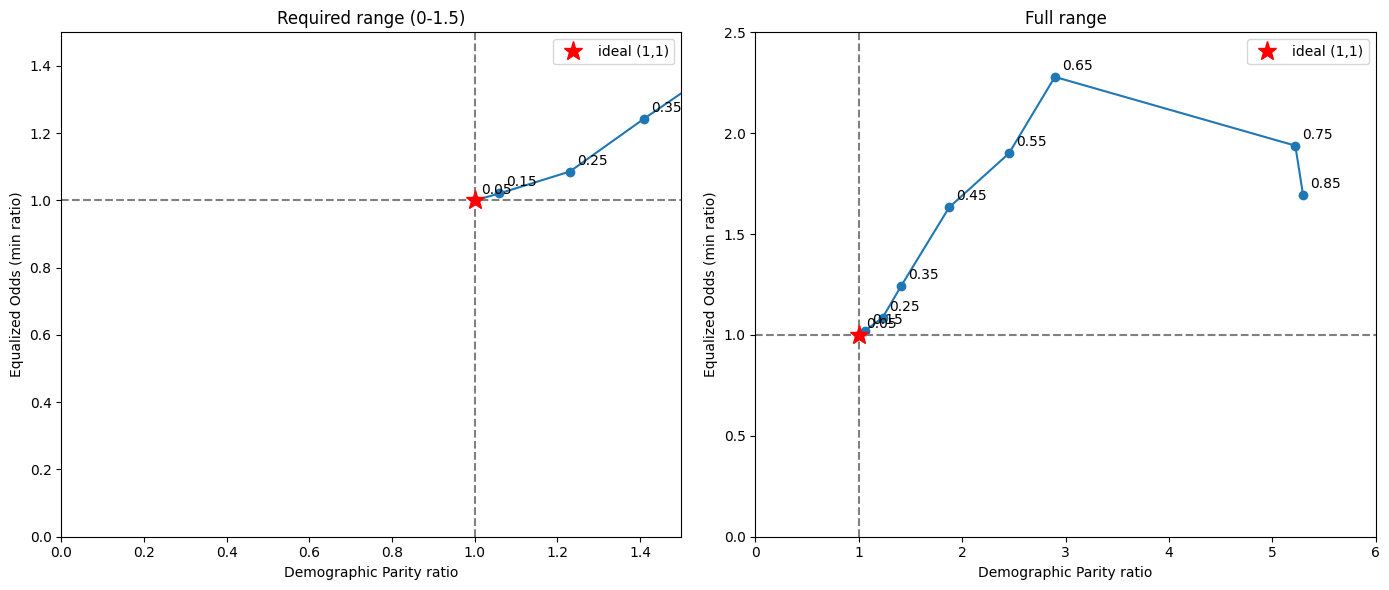

--- t = 0.55 -> t = 0.25 ---
DP: 2.453 -> 1.230 | gap from 1: 1.453 -> 0.230 (-84.1% change in gap)
EO: 1.901 -> 1.086 | gap from 1: 0.901 -> 0.086 (-90.4% change in gap)
PP: 1.027 -> 1.171 | gap from 1: 0.027 -> 0.171 (+522.1% change in gap)
accuracy: 0.674 -> 0.545 (-19.1%)
--- t = 0.55 -> t = 0.35 ---
DP: 2.453 -> 1.410 | gap from 1: 1.453 -> 0.410 (-71.8% change in gap)
EO: 1.901 -> 1.243 | gap from 1: 0.901 -> 0.243 (-73.0% change in gap)
PP: 1.027 -> 1.169 | gap from 1: 0.027 -> 0.169 (+517.8% change in gap)
accuracy: 0.674 -> 0.602 (-10.7%)
--- t = 0.45 -> t = 0.25 ---
DP: 1.874 -> 1.230 | gap from 1: 0.874 -> 0.230 (-73.7% change in gap)
EO: 1.633 -> 1.086 | gap from 1: 0.633 -> 0.086 (-86.4% change in gap)
PP: 1.155 -> 1.171 | gap from 1: 0.155 -> 0.171 (+9.9% change in gap)
accuracy: 0.663 -> 0.545 (-17.7%)

Closest to ideal on DP: t = 0.05 | on EO: t = 0.05 | on PP: t = 0.55


In [23]:
te = df.loc[test_idx].copy(); te["p"] = p_B
A = te[te.race == "African-American"]; B = te[te.race == "Caucasian"]
def sdiv(a, b): return a / b if b not in (0, 0.0) and not np.isnan(b) else np.nan
def rates(g, t):
    yh = (g.p >= t).astype(int); yy = g.is_recidivist
    sel = yh.mean()
    tpr = sdiv(((yh==1)&(yy==1)).sum(), (yy==1).sum())
    fpr = sdiv(((yh==1)&(yy==0)).sum(), (yy==0).sum())
    ppv = sdiv(((yh==1)&(yy==1)).sum(), (yh==1).sum())
    return sel, tpr, fpr, ppv
rows = []
for t in np.round(np.arange(0.05, 0.96, 0.10), 2):
    sA, tA, fA, pA = rates(A, t); sB, tB, fB, pB = rates(B, t)
    DP = sdiv(sA, sB)
    EO = np.nanmin([sdiv(tA, tB), sdiv(fA, fB)]) if not (np.isnan(sdiv(tA,tB)) and np.isnan(sdiv(fA,fB))) else np.nan
    PP = sdiv(pA, pB)
    acc = (((te.p >= t).astype(int)) == te.is_recidivist).mean()
    rows.append(dict(t=t, DP=DP, EO=EO, PP=PP, TPR_ratio=sdiv(tA,tB), FPR_ratio=sdiv(fA,fB), accuracy=acc,
                     sel_A=sA, sel_B=sB, TPR_A=tA, TPR_B=tB, FPR_A=fA, FPR_B=fB, PPV_A=pA, PPV_B=pB))
fair = pd.DataFrame(rows).set_index("t")
display(fair.round(3)); fair.round(4).to_csv("results/part24_fairness.csv")
print("Test group sizes: A =", len(A), "B =", len(B))
print("Base rate of recidivism in test: A = %.3f | B = %.3f" % (A.is_recidivist.mean(), B.is_recidivist.mean()))

# Trade-off chart: required range (0-1.5) and full range
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, (xl, yl), ttl in zip(axs, [(1.5, 1.5), (6.0, 2.5)], ["Required range (0-1.5)", "Full range"]):
    ax.plot(fair.DP, fair.EO, "-o", color="tab:blue")
    for t, r in fair.iterrows():
        if not (np.isnan(r.DP) or np.isnan(r.EO)):
            ax.annotate(f"{t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=(5, 5))
    ax.axvline(1, ls="--", c="grey"); ax.axhline(1, ls="--", c="grey")
    ax.plot(1, 1, "r*", ms=14, label="ideal (1,1)")
    ax.set_xlim(0, xl); ax.set_ylim(0, yl)
    ax.set_xlabel("Demographic Parity ratio"); ax.set_ylabel("Equalized Odds (min ratio)")
    ax.set_title(ttl); ax.legend()
plt.tight_layout(); plt.savefig("results/tradeoff_chart.png", dpi=200); plt.show()

# Trade-off cost between two chosen thresholds
def cmp_thr(t1, t2):
    a, b = fair.loc[round(t1, 2)], fair.loc[round(t2, 2)]
    print(f"--- t = {t1} -> t = {t2} ---")
    for m in ["DP", "EO", "PP"]:
        g1, g2 = abs(1 - a[m]), abs(1 - b[m])
        print(f"{m}: {a[m]:.3f} -> {b[m]:.3f} | gap from 1: {g1:.3f} -> {g2:.3f} ({100*(g2-g1)/g1:+.1f}% change in gap)")
    print(f"accuracy: {a.accuracy:.3f} -> {b.accuracy:.3f} ({100*(b.accuracy-a.accuracy)/a.accuracy:+.1f}%)")
cmp_thr(0.55, 0.25)
cmp_thr(0.55, 0.35)
cmp_thr(0.45, 0.25)

print("\nClosest to ideal on DP: t =", (fair.DP-1).abs().idxmin(), "| on EO: t =", (fair.EO-1).abs().idxmin(), "| on PP: t =", (fair.PP-1).abs().idxmin())

## Done
All outputs are saved to `results/`. Use the printed values (not memory) when writing Parts 3 and 4 of the PDF.